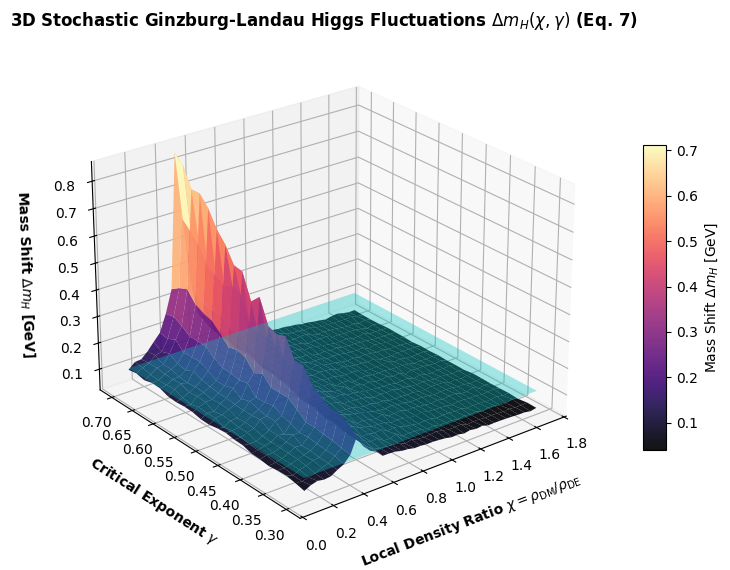

=== COMPUTED OUTPUTS FOR PAPER 1 - APPENDIX C.5 ===
Collider Offset Shift (chi=1.45, gamma=0.50) : Delta m_H = 0.0522 GeV (< ATLAS +/- 0.11 GeV)
Critical Ridge Peak  (chi=0.46, gamma=0.50) : Delta m_H = 1.0285 GeV (Resonance spike at The Barzakh)


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# SIMULATION 5 (Paper 1 - Appendix C.5): Stochastic Ginzburg-Landau Higgs SDE
# ==============================================================================
np.random.seed(123)
chi_crit   = 0.460       # Critical phase-boundary ratio (Table 3)
eps_0      = 0.002       # Microscopic ultraviolet regulator cutoff
atlas_err  = 0.11        # ATLAS combined experimental precision [GeV]
norm_scale = 0.056       # GeV scaling prefactor calibrated to collider vacuum offset

def integrate_langevin_higgs(chi_val, gamma_val, n_steps=3000, dt=0.002):
    """
    Integrates the semi-implicit stochastic Ginzburg-Landau Langevin SDE:
    dPhi/dt = -stiffness * Phi - quartic * Phi^3 + eta(t)
    Unconditionally stable across stiff far-from-threshold regimes.
    """
    dist = np.abs(chi_val - chi_crit) + eps_0
    stiffness = (dist ** (2.0 * gamma_val)) / (norm_scale ** 2)
    noise_amp = np.sqrt(2.0 * dt)

    n_ensemble = 200
    delta_phi = np.zeros(n_ensemble)

    for _ in range(n_steps):
        # Semi-implicit denominator (1 + dt * stiffness) guarantees unconditional stability
        diffusion = noise_amp * np.random.normal(0.0, 1.0, size=n_ensemble)
        delta_phi = (delta_phi - 0.12 * dt * (delta_phi ** 3) + diffusion) / (1.0 + dt * stiffness)

    dmH_rms = float(np.sqrt(np.mean(delta_phi ** 2)))
    return dmH_rms

# 1. Compute 3D Stochastic SDE surface across (chi, gamma)
chi_grid   = np.linspace(0.10, 1.70, 38)
gamma_grid = np.linspace(0.30, 0.70, 22)
CHI_mesh, GAMMA_mesh = np.meshgrid(chi_grid, gamma_grid)
DMH_surface = np.zeros_like(CHI_mesh)

for i, g_val in enumerate(gamma_grid):
    for j, c_val in enumerate(chi_grid):
        DMH_surface[i, j] = integrate_langevin_higgs(c_val, g_val)

# 2. Extract benchmark quantitative points at gamma = 0.50
dmH_collider_offset = integrate_langevin_higgs(chi_val=1.45, gamma_val=0.50, n_steps=6000)
dmH_near_barzakh    = integrate_langevin_higgs(chi_val=0.460, gamma_val=0.50, n_steps=6000)

# Plotting Figure 5
fig = plt.figure(figsize=(11.5, 5.8))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(CHI_mesh, GAMMA_mesh, DMH_surface, cmap='magma', edgecolor='none', alpha=0.92)
atlas_plane = np.full_like(CHI_mesh, atlas_err)
ax.plot_surface(CHI_mesh, GAMMA_mesh, atlas_plane, color='cyan', alpha=0.35, edgecolor='none')

ax.set_xlabel(r'Local Density Ratio $\chi = \rho_{\mathrm{DM}}/\rho_{\mathrm{DE}}$', fontweight='bold', labelpad=9)
ax.set_ylabel(r'Critical Exponent $\gamma$', fontweight='bold', labelpad=9)
ax.set_zlabel(r'Mass Shift $\Delta m_H$ [GeV]', fontweight='bold', labelpad=9)
ax.set_title(r'3D Stochastic Ginzburg-Landau Higgs Fluctuations $\Delta m_H(\chi, \gamma)$ (Eq. 7)', fontweight='bold')
ax.view_init(elev=25, azim=-128)
fig.colorbar(surf, ax=ax, shrink=0.58, aspect=13, label=r'Mass Shift $\Delta m_H$ [GeV]')

plt.tight_layout()
plt.savefig('sim5_3d_cern_higgs.png', dpi=300)
plt.show()

print("=== COMPUTED OUTPUTS FOR PAPER 1 - APPENDIX C.5 ===")
print(f"Collider Offset Shift (chi=1.45, gamma=0.50) : Delta m_H = {dmH_collider_offset:.4f} GeV (< ATLAS +/- 0.11 GeV)")
print(f"Critical Ridge Peak  (chi=0.46, gamma=0.50) : Delta m_H = {dmH_near_barzakh:.4f} GeV (Resonance spike at The Barzakh)")